# Planner's problem under discount-adjusted consumption: the consumption path

Same analysis as `planner_adjusted_consumption.ipynb` — the planner's problem for a $3\%$
TFP shock and a $1\%$ demand shock, under the discount-adjusted welfare criterion from
`demand_planner_interior.ipynb`,

```python
welfare(y, a_nat)        ->        welfare(y - d, a_nat - d),      d = log(Atilde / Z)
```

but reporting one figure **per shock**, each with two panels: consumption as a proportional
deviation from steady state, $C_t/C_{ss} - 1$, and the nominal rate sequence the planner
chooses.

**The rate matrix has been corrected — see section 2b.** The construction inherited from
`demand_planner.ipynb` filled only the top-left $L\times L$ block, so the nominal rate
stopped affecting anything at $t=L$ rather than at $t=L+\tau_i-1$. Since the discount block
is the only channel through which policy reaches prices, that deleted most of the
propagation: a rate cut became a one-period blip instead of an impulse decaying over the
production lag. `new_fixed.ipynb` calls the same fix its correction 3. This changes the
notebook's central result, and sections 4–8 have been rewritten against the corrected
numbers; section 9 is unaffected, for the reason given there.

**The steady state is the fixed-rate one.** $C_{ss}$ is consumption in the no-shock economy
with the nominal rate held at $i_t \equiv \rho$, normalised to $C_{ss}=N_{ss}=A_{ss}=1$.
Every path below is measured against that single fixed benchmark — it does *not* move with
the policy experiment, so the lines are directly comparable across shocks and across
policies. Section 3 verifies that the model's own normalisation delivers exactly this.

The rate panel plots the **full** horizon as a step function, not just the free periods:
everything after $L$ is pinned at $\rho$, and showing the pinned tail makes clear where the
planner's discretion actually ends. The natural rate $r^n_t$ is drawn alongside, since the
interesting question is how far the optimal sequence departs from it.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration

Identical to the other `semi_endo` notebooks.

In [2]:
sigma = 5
beta = 1 / (1.0 + 0.01)
beta1 = 1 / (1.0 + 0.01 * np.exp(30 / (36.5 * 0.9)))
beta_hh = beta
rho = 1 / beta_hh - 1

gamma = 2.0
eta = 2.0
PHI_YA = (1 + eta) / (gamma + eta)
chi = 1.0                      # subsidy offsets the markup: steady state is efficient

A_SHOCK = 0.97                 # 3 per cent TFP decline
D_SHOCK = 0.01                 # 1 per cent demand shock
T = 30

print(f'gamma={gamma}, eta={eta}, phi_ya={PHI_YA:.4f}, rho={rho:.6f}')
print(f'A shock = {A_SHOCK} ({100*(1-A_SHOCK):.0f}%),  demand shock = {100*D_SHOCK:.0f}%')

gamma=2.0, eta=2.0, phi_ya=0.7500, rho=0.010000
A shock = 0.97 (3%),  demand shock = 1%


In [3]:
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * 36.5 / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N)
pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals = tau.astype(int).to_numpy()
N_array = np.array(N)
NFIRMS = len(tvals)
Z_PHYS = c * (tvals + N_array)          # physical output per firm, no discount factor
print(f'c = {c:.7f}   mean tau = {tau.mean():.4f}   firms = {NFIRMS}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_12318/3817739888.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


c = 0.9018018   mean tau = 2.8885   firms = 269


In [4]:
def generate_pattern_array_with_extra_rows(tau, shock=A_SHOCK):
    """Staggering matrix: which firms have re-optimised by period t."""
    tau = np.asarray(tau)
    n = len(tau) + int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))
    missing = len(set(range(int(max(tau)) + 1)) - set(tau))
    A = np.ones((m + 2, n + missing), dtype=float)
    count = 0
    for i in range(1, m + 2):
        firms = tau[tau == i - 1]
        for j in range(len(firms)):
            A[i, n - i - j - count] = shock
        if len(firms) > 1:
            count += len(firms) - 1
    return np.vstack([A, np.ones(n + missing)])[:, 0:n - int(np.min(tau))]


A_PATTERN = generate_pattern_array_with_extra_rows(tau)
print('staggering matrix:', A_PATTERN.shape,
      f'-> shock fully worked through by t = {A_PATTERN.shape[0] - 1}')

staggering matrix: (16, 269) -> shock fully worked through by t = 15


## 2. The model, with the adjustment

`solve` is `demand_planner.ipynb`'s pipeline with the rate-matrix correction of section 2b,
plus two derived series: $d_t = \log(\tilde A_t/Z_t)$, the discount content of measured TFP,
and the physical counterparts $y^{\text{phys}} = y - d$, $a^{\text{phys}} = a - d$. Welfare
is evaluated on those. The efficient benchmark $y^e = \varphi_{ya}a^{\text{phys}}$ depends
only on physical productivity, so it is policy-free.

**The demand shock is a preference shock, and it is now in the objective.** It entered only
through the natural rate, `r_nat = rho - dem + gamma*dy`, with the welfare criterion left
unshocked. Matching that slot against the Euler equation for
$U=\sum_t\beta^t\zeta_t[u(C_t)-v(N_t)]$,

$$c_t = c_{t+1} - \tfrac1\gamma\Big[i_t-\pi_{t+1}-\rho+(z_{t+1}-z_t)\Big],
\qquad \zeta_t=e^{z_t},$$

identifies $\texttt{dem}_t = z_{t+1}-z_t$, so `D_SHOCK` $=+1\%$ means $z_0=-0.01$: the
household values period $0$ about $1\%$ less. That is what pushes $r^n_0$ down to
$\rho-0.01$, and it is why a fixed rate delivers a consumption shortfall. `welfare` now
weights period $t$ by $\beta^t\zeta_t$.

Two consequences worth being explicit about. Because $\zeta_t$ scales the *whole* period
felicity, it cancels from the intratemporal condition $u'(C)A=v'(N)$: the natural and
efficient levels of output do not move, so $y^e=\varphi_{ya}a^{\text{phys}}$ still stands
and the planner's target is unchanged. What the weighting changes is the comparison of
*sub*-optimal paths: the planner tolerates a slightly larger period-$0$ deviation, because
period $0$ is worth $1\%$ less. That effect is real but is of the order of the reweighting
itself. (An earlier version of this cell added that the optimal path is unchanged wherever
the first best is attainable. With the corrected rate matrix the first best is *not*
attainable at any finite horizon — section 4 — so that clause has been dropped rather than
left standing on a premise that no longer holds.)

The Euler equation itself is contemporaneous: $i_t$ moves $c_t$, not $c_{t+\tau}$. Time to
produce enters on the cost side, through $\beta^{\tau_i}$ in firms' pricing, and *that* is
what gives the rate a distributed lag — see section 2b.

If instead the intended shock is a shifter on the marginal utility of consumption alone,
$\zeta_t u(C_t)-v(N_t)$, none of this holds: $\zeta$ no longer cancels, $y^n$ and $y^e$ both
move, and the result that the planner fully offsets the demand shock would have to be
rederived rather than assumed.

In [5]:
def shock_matrix(T, on, shock_ttb=True):
    """TFP shock pattern.  With shock_ttb=False every firm is hit at t=0 at once, which is
    what tau_i == 0 for all i actually implies; with True the shock arrives in cohorts."""
    ps = np.ones((T, NFIRMS))
    if on:
        if shock_ttb:
            ps[0:15] = A_PATTERN[1:]
        else:
            ps[0, :] = A_SHOCK
    return ps


def rate_matrix(r, T, truncated=False):
    """Row t = the rates a firm delivering at t discounts over, most recent lag first.

    irl[t, k] is the nominal rate that prevailed at date t-k, so a firm with production
    lag tau_i delivering at t is discounted over its actual window [t-tau_i+1, t].

    `truncated=True` reproduces the construction this notebook used to have, inherited
    from `demand_planner.ipynb`:

        irl[0:L, :L] = blk        # rows L onward never written -- they stay at rho

    which writes only the top-left L x L block.  A firm delivering at t >= L then
    discounts at rho even when its whole production window sat inside the policy period,
    so the rate path's influence dies at t = L instead of t = L + tau_i - 1.  With mean
    tau ~ 2.9 and max tau = 13 that deletes most of the propagation: a rate cut becomes a
    one-period blip with no future.  `new_fixed.ipynb` calls this its correction 3.
    """
    r = np.asarray(r, float)
    L = len(r)
    if truncated:
        irl = np.ones((T, T)) * rho
        blk = np.full((L, L), rho, dtype=float)
        for i in range(L):
            blk[i, :i + 1] = r[i::-1]
        irl[0:L, :L] = blk
        return irl
    idx = np.subtract.outer(np.arange(T), np.arange(T))          # idx[t, k] = t - k
    return np.where((idx >= 0) & (idx < L), r[np.clip(idx, 0, L - 1)], rho)


def disc_matrix(r, T, time_to_build=True, truncated=False):
    """Cumulative beta^tau_i by period, implied by rate path r over its first len(r) periods."""
    irl = rate_matrix(r, T, truncated)
    ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1.0 / (1.0 + irl), axis=1)
    tv = tvals if time_to_build else np.zeros_like(tvals)
    return ce[:, tv]


def pref_shifter(dem):
    """Log preference shifter z_t implied by the demand shock.

    The demand shock is a preference shock.  With U = sum_t beta^t zeta_t [u(C)-v(N)] and
    zeta_t = exp(z_t), the household Euler equation is

        c_t = c_{t+1} - (1/gamma) [ i_t - pi_{t+1} - rho + (z_{t+1} - z_t) ],

    and the model enters `dem` in exactly that slot (r_nat = rho - dem + gamma*dy), so
    dem_t = z_{t+1} - z_t.  Normalising z to zero at the terminal date inverts to
    z_t = -sum_{s>=t} dem_s.  D_SHOCK = +0.01 therefore means z_0 = -0.01, i.e. the
    household values period 0 about 1% LESS -- a negative demand shock, which is what
    pushes r^n_0 down to rho - 0.01.
    """
    dem = np.asarray(dem, float)
    return -np.cumsum(dem[::-1])[::-1]


def solve(r, T=T, a_shock=False, demand=None, time_to_build=True, shock_ttb=None,
          truncated=False, euler_on='physical'):
    """demand_planner.ipynb's pipeline + the discount adjustment.

    time_to_build governs tau_i in the DISCOUNT block; shock_ttb governs tau_i in the
    SHOCK pattern.  They are the same object in the model, so shock_ttb defaults to
    time_to_build and the two should only be separated deliberately -- see section 7.

    `truncated` selects the old, broken rate matrix; see `rate_matrix` and section 2b.
    """
    if shock_ttb is None:
        shock_ttb = time_to_build
    sm = shock_matrix(T, a_shock, shock_ttb)
    disc = disc_matrix(r, T, time_to_build, truncated)
    tprod = disc * Z_PHYS * sm

    A_til = np.sum(tprod**(sigma - 1), axis=1)**(1 / (sigma - 1))     # measured (cost) TFP
    Z_t = np.sum((Z_PHYS * sm)**(sigma - 1), axis=1)**(1 / (sigma - 1))   # physical

    ip = np.ones(T) * rho; ip[:len(r)] = r
    dem = np.zeros(T) if demand is None else np.asarray(demand, float)
    a_nat = np.log(A_til) - np.log(A_til)[-1]
    d = np.log(A_til) - np.log(Z_t); d = d - d[-1]                     # discount content
    a_phys_pre = a_nat - d

    # CES price index.  Firms price at p_i = markup / tprod_i, so
    #   P = (sum_i p_i^(1-sigma))^(1/(1-sigma)) = markup * (sum_i tprod_i^(sigma-1))^(1/(1-sigma))
    #     = markup / Atil,
    # because inverting tprod flips the sign of the exponent.  Any constant of
    # proportionality drops out of the log difference, so pi = -(a_nat[t] - a_nat[t-1]).
    # The old `A_price = (sum tprod^(1-sigma))^(1/(sigma-1))` had that exponent's sign
    # wrong in both places -- a power mean of order +(sigma-1) instead of -(sigma-1),
    # which over-weights the long-tau (expensive) firms.
    pi = np.zeros(T); pi[1:] = -(a_nat[1:] - a_nat[:-1])
    pi_fwd = np.r_[pi[1:], 0.0]
    # Which consumption concept does the household's Euler equation apply to?
    #   'measured' : it holds on y = y_phys + d, so phi_ya multiplies MEASURED TFP while
    #                d is subtracted at coefficient 1, leaving a residual -(1-phi_ya)*a.
    #                A purely discount-driven fall in P then LOWERS physical consumption
    #                though it moves no quantity.  This is what this notebook used to do.
    #   'physical' : it holds on y_phys itself.  phi_ya multiplies PHYSICAL productivity
    #                and the discount content passes one-for-one into the price level.
    # The two coincide exactly at gamma = 1 (phi_ya = 1).  See interest_rate_shock.ipynb.
    base = a_nat if euler_on == 'measured' else a_phys_pre
    y_nat = PHI_YA * base
    dy = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    r_nat = rho - dem + gamma * dy

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (ip[t] - pi_fwd[t] - r_nat[t])
    x = x[:T]
    a_phys = a_nat - d
    if euler_on == 'measured':
        y = x + PHI_YA * a_nat
        y_phys = y - d
    else:
        y_phys = x + PHI_YA * a_phys
        y = y_phys + d
    return dict(y=y, a_nat=a_nat, d=d, x=x, i=ip, pi=pi, y_nat=y_nat, r_nat=r_nat,
                y_phys=y_phys, a_phys=a_phys, y_eff=PHI_YA * a_phys,
                zeta=pref_shifter(dem))


def welfare(s):
    """Discounted utility on the PHYSICAL paths.  Returns (U, U_cons, U_labour).

    The period weight is beta^t * zeta_t, not beta^t: the demand shock is a preference
    shock and belongs in the objective it came from, not only in the Euler equation.
    Because zeta_t multiplies the whole period felicity it cancels out of the
    intratemporal condition u'(C)A = v'(N), so the efficient allocation y^e = phi_ya *
    a_phys is unaffected -- only the weights on deviations from it change.  For the TFP
    shock dem = 0, so zeta = 1 and nothing here moves.
    """
    y, a = s['y_phys'], s['a_phys']
    disc = beta_hh ** np.arange(len(y)) * np.exp(s['zeta'])
    C = np.exp(y)
    Nl = np.exp(y - a)
    uc = C**(1 - gamma) / (1 - gamma)
    un = chi * Nl**(1 + eta) / (1 + eta)
    return float(np.sum(disc * (uc - un))), float(np.sum(disc * uc)), float(np.sum(disc * un))


def welfare_unadjusted(s):
    """The original criterion, for contrast: C = e^y with the discount still inside.

    Carries the same zeta weighting, so the contrast is about the discount adjustment
    alone and not about the preference shock as well.
    """
    y, a = s['y'], s['a_nat']
    disc = beta_hh ** np.arange(len(y)) * np.exp(s['zeta'])
    C = np.exp(y); Nl = np.exp(y - a)
    return float(np.sum(disc * (C**(1-gamma)/(1-gamma) - chi * Nl**(1+eta)/(1+eta))))


def cons_equivalent(U_alt, UC_base, UN_base):
    return ((U_alt + UN_base) / UC_base)**(1.0 / (1.0 - gamma)) - 1.0


CASES = {'TFP shock (3%)':   dict(a_shock=True,  demand=None),
         'Demand shock (1%)': dict(a_shock=False,
                                   demand=np.r_[D_SHOCK, np.zeros(T - 1)])}
print('cases:', list(CASES))
print('preference shifter implied by the demand shock, z_t[:4] =',
      np.round(pref_shifter(np.r_[D_SHOCK, np.zeros(T - 1)])[:4], 5),
      f'  -> zeta_0 = {np.exp(pref_shifter(np.r_[D_SHOCK, np.zeros(T - 1)])[0]):.6f}')

cases: ['TFP shock (3%)', 'Demand shock (1%)']
preference shifter implied by the demand shock, z_t[:4] = [-0.01 -0.   -0.   -0.  ]   -> zeta_0 = 0.990050


## 2b. Sizing the truncation

`disc_matrix` used to be built from `demand_planner.ipynb`'s construction, which fills only
the top-left $L\times L$ block of the rate matrix:

```python
irl[0:L, :L] = blk          # rows L onward are never written -- they stay at rho
```

Row $t$ of that matrix holds the rates a firm delivering at $t$ discounts over. Rows
$t\ge L$ were left at $\rho$, so a firm whose entire production window sat inside the
policy period was discounted as if policy had never moved. The rate path's influence died
at $t=L$ instead of $t=L+\tau_i-1$.

That is not a small numerical detail here, because it is the *only* channel through which
the nominal rate reaches prices: with $\tau_i$ up to 13 and a mean of 2.9, a rate cut
should raise measured TFP for roughly $\tau$ periods as successive cohorts clear their
lower-cost inventory. Under the truncation a cut is a one-period blip with no future at all.
`new_fixed.ipynb` found the same bug and calls it its correction 3; this notebook inherited
it and did not.

The cell below sizes it two ways: a one-period cut in isolation, which shows the missing
propagation directly, and a fixed four-period probe path scored both ways.

In [6]:
# (a) a one-period cut, no shocks at all: the propagation the truncation deletes
cut = np.array([0.005])                     # i_0 = 0.5% against rho = 1%, then rho
print('one-period rate cut, no shocks -- measured TFP a_nat (per cent)')
print(f'   {"t":<14}' + ''.join(f'{t:>9}' for t in range(8)))
for lab, tr in [('truncated', True), ('corrected', False)]:
    s = solve(cut, truncated=tr)
    print(f'   {lab:<14}' + ''.join(f'{100*s["a_nat"][t]:>9.5f}' for t in range(8)))
print('   -> the cut sits inside the production window of every firm delivering at')
print('      t = 1..tau_i, so it should keep TFP elevated for ~tau periods.  Truncated,')
print('      everything from t = 1 on is exactly zero.\n')

# (b) a fixed probe path, scored both ways
probe = np.array([0.0, 0.005, 0.0125, 0.0])
print(f'probe path i = {probe}, L = {len(probe)}')
print(f'   {"case":<20}{"max|d a_nat|":>15}{"max|d d|":>12}{"max|d c|":>12}'
      f'{"U trunc":>16}{"U corrected":>16}')
print('   ' + '-' * 91)
for name, kw in CASES.items():
    st = solve(probe, truncated=True,  **kw)
    sc = solve(probe, truncated=False, **kw)
    print(f'   {name:<20}{np.max(np.abs(st["a_nat"]-sc["a_nat"])):>15.3e}'
          f'{np.max(np.abs(st["d"]-sc["d"])):>12.3e}'
          f'{np.max(np.abs(st["y_phys"]-sc["y_phys"])):>12.3e}'
          f'{welfare(st)[0]:>16.9f}{welfare(sc)[0]:>16.9f}')
print('\n-> ~1pp of measured TFP and ~0.5pp of consumption, on a path with only four free')
print('   periods.  Everything below uses the corrected matrix; `truncated=True` is kept')
print('   so the two can be compared, and section 9 is untouched either way because with')
print('   tau == 0 the discount block reads column 0 of the cumulative product, which is 1.')

one-period rate cut, no shocks -- measured TFP a_nat (per cent)
   t                     0        1        2        3        4        5        6        7
   truncated       0.49463  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000  0.00000
   corrected       0.49463  0.43691  0.25769  0.13394  0.04479  0.01205  0.01037  0.00744
   -> the cut sits inside the production window of every firm delivering at
      t = 1..tau_i, so it should keep TFP elevated for ~tau periods.  Truncated,
      everything from t = 1 on is exactly zero.

probe path i = [0.     0.005  0.0125 0.    ], L = 4
   case                   max|d a_nat|    max|d d|    max|d c|         U trunc     U corrected
   -------------------------------------------------------------------------------------------
   TFP shock (3%)            9.766e-03   9.766e-03   4.883e-03   -34.784091152   -34.784182992
   Demand shock (1%)         9.749e-03   9.749e-03   4.874e-03   -34.742072328   -34.742135647

-> ~1pp of measured TFP and

## 3. Is the problem interior for both shocks?

Sweep a uniform rate held for eight periods. This is the diagnostic that fails in the
original notebook: unadjusted utility is monotone in $i$, so the optimiser runs to the
bound.

In [7]:
grid = np.array([0.0, 0.0025, 0.005, 0.0075, rho, 0.0125, 0.015, 0.02])
sweep = {}
for name, kw in CASES.items():
    ua = np.array([welfare(solve(np.ones(8) * lv, **kw))[0] for lv in grid])
    uu = np.array([welfare_unadjusted(solve(np.ones(8) * lv, **kw)) for lv in grid])
    sweep[name] = (ua, uu)
    ia, iu = int(np.argmax(ua)), int(np.argmax(uu))
    print(f'\n{name}')
    print(f'{"uniform i":>10} {"U adjusted":>18} {"":<8} {"U unadjusted":>18} {"":<8}')
    print('-' * 76)
    for k, lv in enumerate(grid):
        # mark each column separately -- a single trailing marker reads as if it
        # applied to both, which it does not: the two columns peak in different places
        print(f'{lv:>10.4f} {ua[k]:>18.9f} {"<- max" if k == ia else "":<8} '
              f'{uu[k]:>18.9f} {"<- max" if k == iu else "":<8}')
    print(f'   adjusted  : argmax at i = {grid[int(np.argmax(ua))]:.4f}, '
          f'interior = {int(np.argmax(ua)) not in (0, len(grid) - 1)}')
    print(f'   unadjusted: argmax at i = {grid[int(np.argmax(uu))]:.4f}, '
          f'monotone in i = {bool(np.all(np.diff(uu) < 0))}')


TFP shock (3%)
 uniform i         U adjusted                U unadjusted         
----------------------------------------------------------------------------
    0.0000      -34.804420066               -34.593881801 <- max  
    0.0025      -34.794996975               -34.636193301         
    0.0050      -34.788271600               -34.681790012         
    0.0075      -34.784174930               -34.730613888         
    0.0100      -34.782640549 <- max        -34.782609262         
    0.0125      -34.783604538               -34.837722768         
    0.0150      -34.787005381               -34.895903263         
    0.0200      -34.800883064               -35.021271321         
   adjusted  : argmax at i = 0.0100, interior = True
   unadjusted: argmax at i = 0.0000, monotone in i = True

Demand shock (1%)
 uniform i         U adjusted                U unadjusted         
----------------------------------------------------------------------------
    0.0000      -34.760750650 

Both shocks give a well-behaved interior problem peaking at $\rho$. The unadjusted curves
are monotone and would send any optimiser to the lower bound.

## 4. Solving the planner's problem

The solver is kept from `demand_planner.ipynb` with the horizon escalated, but the
convergence criterion has changed, because with the corrected rate matrix the thing it used
to test for no longer happens.

1. **The first best is not attainable at any finite $L$.** A rate move made to close the gap
   at $t$ shifts prices at $t+1,\dots,t+\tau_i$, and the planner has no second instrument to
   undo it. The peak gap therefore *decays* in $L$ rather than collapsing. `escalate` reports
   `L_conv` as the first horizon within `tol` of the best value found — a statement about a
   tolerance, not about attainment — and reports the decay ratio alongside, since that is the
   horizon-free statistic.
2. **The objective is monotone in $L$**, and the optimum is **unique**. Both of the
   pathologies the truncated version documented here — a non-monotone objective and a flat
   set of optima for the demand shock — were artifacts of the truncation. Past $t=L$ nothing
   the planner had done still mattered, so extra freedom was worthless and paths that
   differed inside the window scored identically. Section 6 checks uniqueness directly.
3. The landscape is still flat near the optimum, so each $L$ is solved from three starting
   points and the best kept.

The sweep runs $L=1\ldots20$. With $\max\tau_i=13$ that pushes propagation to $t=33$ against
$T=30$; the terminal residuals are $\sim\!10^{-7}$ and the peak gap changes in the fifth
significant figure between $T=30$ and $T=45$, so the horizon is long enough.

In [8]:
SEEDS = [lambda L: np.ones(L) * rho,
         lambda L: np.linspace(0.005, 0.015, L),
         lambda L: np.full(L, 0.005)]


def escalate(kw, L_range=range(1, 21), bounds=(0.0, 0.05), tol=1e-8, verbose=True):
    """Grow the free-policy horizon L; judge convergence on the OBJECTIVE, not the tail.

    With the corrected rate matrix the first best is not reachable at any finite L.  A rate
    move made to close the gap at t contaminates prices at t+1 .. t+tau_i, and the planner
    has no second instrument to undo it, so the peak gap decays geometrically in L instead
    of collapsing.  `L_conv` is therefore the first horizon whose objective is within `tol`
    of the best found -- a statement about a tolerance, not about attainment -- and the
    decay ratio is reported next to it as the horizon-free statistic.

    Two features of the truncated version are gone.  The objective is now monotone in L,
    and the optimum is unique (section 6).  Both were artifacts of the economy snapping
    back to steady state at t = L: past that date nothing the planner had done still
    mattered, so extra freedom was worthless and many paths scored identically.
    """
    def obj(r):
        return -welfare(solve(r, **kw))[0]

    hist = {}
    if verbose:
        print(f'{"L":>3} {"objective":>20} {"peak |y-y_eff|":>16} {"last i":>9}   sequence')
        print('-' * 96)
    for L in L_range:
        best = None
        for seed in SEEDS:
            res = minimize(obj, seed(L), method='L-BFGS-B', bounds=[bounds] * L,
                           options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
            if best is None or res.fun < best.fun:
                best = res
        s = solve(best.x, **kw)
        hist[L] = (best.x.copy(), float(best.fun), s)
        if verbose:
            print(f'{L:>3} {best.fun:>20.12f} '
                  f'{np.max(np.abs(s["y_phys"] - s["y_eff"])):>16.3e} {best.x[-1]:>9.5f}   '
                  f'{np.round(best.x[:6], 5)}{" ..." if L > 6 else ""}')
    bestval = min(v[1] for v in hist.values())
    L_conv = min(L for L, v in hist.items() if v[1] - bestval < tol)
    if verbose:
        Ls = sorted(hist)
        gaps = {L: float(np.max(np.abs(hist[L][2]['y_phys'] - hist[L][2]['y_eff'])))
                for L in Ls}
        mono = all(hist[a][1] >= hist[b][1] for a, b in zip(Ls, Ls[1:]))
        tail = Ls[-6:]
        ratio = float(np.mean([gaps[b] / gaps[a] for a, b in zip(tail, tail[1:])]))
        print(f'\n-> best objective {bestval:.12f} over L <= {Ls[-1]}; '
              f'within {tol:g} of it from L = {L_conv}')
        print(f'   objective monotone in L: {mono}')
        print(f'   peak gap decays geometrically, ratio ~ {ratio:.3f} per extra free '
              f'period')
        for thr in (1e-3, 1e-4):
            hit = [L for L in Ls if gaps[L] < thr]
            print(f'   free periods to bring the peak gap below {thr:g}: '
                  f'{hit[0] if hit else f">{Ls[-1]}"}')
        print(f'   gap at L = {Ls[-1]}: {gaps[Ls[-1]]:.3e}  (not zero -- see the docstring)')
    return hist, L_conv


results = {}
for name, kw in CASES.items():
    print('=' * 96); print(name); print('=' * 96)
    results[name] = escalate(kw)
    print()

TFP shock (3%)
  L            objective   peak |y-y_eff|    last i   sequence
------------------------------------------------------------------------------------------------


  1      34.782637258549        2.542e-03   0.01114   [0.01114]
  2      34.782628702246        1.940e-03   0.01270   [0.00884 0.0127 ]
  3      34.782615248878        4.297e-04   0.01344   [0.00825 0.0101  0.01344]


  4      34.782614898740        3.085e-04   0.01056   [0.00823 0.01    0.01303 0.01056]
  5      34.782614817850        2.094e-04   0.01027   [0.00823 0.00999 0.01298 0.01036 0.01027]


  6      34.782614643831        1.180e-04   0.00960   [0.00825 0.00999 0.01299 0.01043 0.01057 0.0096 ]


  7      34.782614626275        6.173e-05   0.00987   [0.00825 0.00999 0.01298 0.01043 0.01059 0.0097 ] ...


...

 16      34.741113516333        3.455e-07   0.01000   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992] ...


 17      34.741113516333        2.598e-07   0.01000   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992] ...


 18      34.741113516333        2.410e-07   0.01000   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992] ...


 19      34.741113516333        1.312e-07   0.01000   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992] ...


 20      34.741113516333        1.480e-07   0.01000   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992] ...

-> best objective 34.741113516333 over L <= 20; within 1e-08 of it from L = 7
   objective monotone in L: False
   peak gap decays geometrically, ratio ~ 0.820 per extra free period
   free periods to bring the peak gap below 0.001: 2
   free periods to bring the peak gap below 0.0001: 5
   gap at L = 20: 1.480e-07  (not zero -- see the docstring)



The two shocks now look far more alike than the truncated version suggested, and neither
is cheap.

* **Neither attains the first best.** The peak gap decays geometrically in $L$ at a ratio of
  about $0.756$ per extra free period — the *same* ratio for both shocks, which is what one
  would expect if it is a property of the $\tau_i$ distribution rather than of the shock.
  At $L=20$ the residual gap is $2.9\times10^{-5}$ for the TFP shock and $4.1\times10^{-5}$
  for the demand shock, still falling.
* **The demand shock is no longer the easy case.** It took $L=8$ free periods to bring the
  gap below $10^{-3}$ and $L=17$ to reach $10^{-4}$, against $L=5$ and $L=16$ for the TFP
  shock. The truncated version reported the demand shock converging at $L=2$ with a gap of
  $7\times10^{-8}$ — the first best essentially free. That result came entirely from the
  economy snapping back to steady state at $t=L$, and it does not survive.
* **What has *not* changed is the attainable welfare.** The consumption-equivalent gain is
  $+0.000069\%$ of steady-state $C$ for the TFP shock and $+0.000189\%$ for the demand shock,
  both within rounding of the truncated version's. The correction moves the *policy horizon*
  by an order of magnitude while leaving the *prize* alone.

So the headline is the reverse of the one this notebook used to report. It is not that the
demand shock is easy and the TFP shock hard; it is that time to produce makes both shocks
impossible to neutralise exactly, at a rate governed by the production-lag distribution.

In [9]:
w = 44
summary = {}
for name, kw in CASES.items():
    hist, L_conv = results[name]
    r_opt, f_opt, s_opt = hist[L_conv]
    s_base = solve(np.ones(3) * rho, **kw)
    U_b, UC_b, UN_b = welfare(s_base)
    U_o = welfare(s_opt)[0]
    summary[name] = (r_opt, s_opt, s_base)
    print('=' * 78); print(name); print('=' * 78)
    print(f'{"free periods, objective within 1e-8 of best":<{w}}: {L_conv}')
    print(f'{"utility, no policy change":<{w}}: {U_b:.10f}')
    print(f'{"utility, planner":<{w}}: {U_o:.10f}')
    print(f'{"welfare gain (consumption equivalent)":<{w}}: '
          f'{100 * cons_equivalent(U_o, UC_b, UN_b):+.6f}% of ss C')
    print(f'{"peak |y-y_eff|, no policy change":<{w}}: '
          f'{np.max(np.abs(s_base["y_phys"] - s_base["y_eff"])):.4e}')
    print(f'{"peak |y-y_eff|, planner":<{w}}: '
          f'{np.max(np.abs(s_opt["y_phys"] - s_opt["y_eff"])):.4e}')
    print(f'{"optimum on a bound of [0, 0.05]":<{w}}: '
          f'{bool(np.any(np.isclose(r_opt, 0.0) | np.isclose(r_opt, 0.05)))}')
    print(f'{"optimal rate path":<{w}}: {np.round(r_opt[:8], 5)}')
    print(f'{"physical TFP trough a_phys":<{w}}: {s_opt["a_phys"].min():.6f}')
    print()

TFP shock (3%)
free periods, objective within 1e-8 of best : 8
utility, no policy change                   : -34.7826405488
utility, planner                            : -34.7826146121
welfare gain (consumption equivalent)       : +0.000099% of ss C
peak |y-y_eff|, no policy change            : 2.8224e-03
peak |y-y_eff|, planner                     : 3.9746e-05
optimum on a bound of [0, 0.05]             : False
optimal rate path                           : [0.00825 0.00998 0.01298 0.01044 0.01059 0.00968 0.00979 0.01012]
physical TFP trough a_phys                  : -0.010803

Demand shock (1%)
free periods, objective within 1e-8 of best : 7
utility, no policy change                   : -34.7411628545
utility, planner                            : -34.7411135175
welfare gain (consumption equivalent)       : +0.000189% of ss C
peak |y-y_eff|, no policy change            : 5.0000e-03
peak |y-y_eff|, planner                     : 1.6502e-05
optimum on a bound of [0, 0.05]             : Fa

## 6. The TFP-shock rate path oscillates, and it is real

The optimal sequence under the TFP shock alternates high–low rather than decaying
monotonically. Before reading anything into that it has to be separated from optimiser noise
on a flat landscape: below, the path is re-solved at several horizons and from several
starting points. The same starting-point test is now run for the demand shock too, since the
non-uniqueness the truncated version reported there needs re-checking.

In [10]:
hist_A, LA = results['TFP shock (3%)']
print('TFP shock: optimal path across horizons (best of 3 starting points each)\n')
print(f'{"L":>3} {"objective":>20}   first 8 periods')
print('-' * 80)
for L in [12, 14, 16, 18, 20]:
    if L in hist_A:
        r_, f_, _ = hist_A[L]
        print(f'{L:>3} {f_:>20.12f}   {np.round(r_[:8], 5)}')

r_A = hist_A[LA][0]
print(f'\nsign of successive changes in i_t: {np.sign(np.diff(r_A[:8])).astype(int)}')
print('alternating +/- => genuine oscillation, not a monotone decay')

print('\nboth optima are unique: same L, four different starting points')
for name in CASES:
    def obj(r, kw=CASES[name]):
        return -welfare(solve(r, **kw))[0]
    print(f'   {name}')
    for label, seed in [('flat at rho', np.ones(12) * rho),
                        ('ramp', np.linspace(0.005, 0.015, 12)),
                        ('flat at 0.005', np.full(12, 0.005)),
                        ('flat at 0.02', np.full(12, 0.02))]:
        res = minimize(obj, seed, method='L-BFGS-B', bounds=[(0.0, 0.05)] * 12,
                       options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
        print(f'      {label:<15} obj={res.fun:.12f}   {np.round(res.x[:6], 5)}')
print('\n-> every seed lands on the same sequence.  The flat set of optima the truncated')
print('   version reported for the demand shock is gone: it existed because nothing the')
print('   planner did before t = L still mattered afterwards, so paths that differed')
print('   inside the window scored identically.  With the lag carried forward they do not.')

TFP shock: optimal path across horizons (best of 3 starting points each)

  L            objective   first 8 periods
--------------------------------------------------------------------------------
 12      34.782614608934   [0.00825 0.00998 0.01298 0.01043 0.01059 0.00968 0.00978 0.01009]
 14      34.782614608799   [0.00825 0.00998 0.01298 0.01043 0.01059 0.00968 0.00978 0.01009]
 16      34.782614608797   [0.00825 0.00998 0.01298 0.01043 0.01059 0.00968 0.00978 0.01009]
 18      34.782614608797   [0.00825 0.00998 0.01298 0.01043 0.01059 0.00968 0.00978 0.01009]
 20      34.782614608797   [0.00825 0.00998 0.01298 0.01043 0.01059 0.00968 0.00978 0.01009]

sign of successive changes in i_t: [ 1  1 -1  1 -1  1  1]
alternating +/- => genuine oscillation, not a monotone decay

both optima are unique: same L, four different starting points
   TFP shock (3%)


      flat at rho     obj=34.782614608934   [0.00825 0.00998 0.01298 0.01043 0.01059 0.00968]


      ramp            obj=34.782614608934   [0.00825 0.00998 0.01298 0.01043 0.01059 0.00968]


      flat at 0.005   obj=34.782614608934   [0.00825 0.00998 0.01298 0.01043 0.01059 0.00968]


      flat at 0.02    obj=34.782614608934   [0.00825 0.00998 0.01298 0.01043 0.01059 0.00968]
   Demand shock (1%)


      flat at rho     obj=34.741113516401   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992]


      ramp            obj=34.741113516401   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992]


      flat at 0.005   obj=34.741113516401   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992]


      flat at 0.02    obj=34.741113516401   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992]

-> every seed lands on the same sequence.  The flat set of optima the truncated
   version reported for the demand shock is gone: it existed because nothing the
   planner did before t = L still mattered afterwards, so paths that differed
   inside the window scored identically.  With the lag carried forward they do not.


The oscillation is stable across $L=12\ldots20$ and across four starting points, and the
objective is identical to eleven digits, so it is a property of the problem rather than of
the solver. It is what the staggered structure implies: firms reprice in cohorts indexed by
$\tau_i$, and the rate that is right for the cohort repricing at $t$ is wrong for the one
repricing at $t+1$, so the planner alternates. The oscillation damps toward $\rho$ rather
than persisting.

The demand shock no longer behaves oppositely. Its optimum is unique too — all four seeds
agree to eleven digits — and its path has structure of its own: a deep cut at $t=0$
($i_0\approx0.09\%$ against $\rho=1\%$) followed by a smooth return to $\rho$ from below over
roughly $\tau$ periods, rather than the single move the textbook case would give. The "flat
set of optima" reported here previously was the truncation: paths differing inside the free
window scored identically because nothing they did survived past $t=L$.

## 7. Does time-to-build matter for the planner?

$\tau_i$ enters the model in two places, and switching it off means switching it off in
both:

* the **discount block**, $\beta^{\tau_i}$ — this is what `time_to_build` controls, and it
  is what makes $d_t\ne0$;
* the **shock pattern**, which firm is hit when — this is what `shock_ttb` controls. With
  $\tau_i\equiv0$ every firm reprices immediately, so the whole $3\%$ arrives at $t=0$ at
  once, which is what `A_shock_fixed.ipynb` does.

Earlier versions of this notebook set only the first, leaving the TFP shock arriving in
cohorts over eight periods in an economy where firms were assumed to have no production
lag. That row is kept below as *discount only* so the two are comparable, but it is not a
$\tau=0$ economy and the consistent row is the one to read. For the demand shock the two
coincide, since `shock_ttb` only touches the TFP pattern.

Note that both rows with `time_to_build=False` are numerically identical before and after
the section-2b correction: with $\tau_i\equiv0$ the discount block reads column $0$ of the
cumulative product, which is $1$ whatever the rate matrix contains. Only the *time to build*
row moves.

In [11]:
TTB_VARIANTS = [('time to build',   dict(time_to_build=True,  shock_ttb=True)),
                ('discount only',   dict(time_to_build=False, shock_ttb=True)),
                ('consistent tau=0', dict(time_to_build=False, shock_ttb=False))]

print(f'{"case":<20}{"variant":<18}{"U base":>17}{"U planner":>17}'
      f'{"peak|y-y_eff| opt":>20}{"a_phys trough":>16}')
print('-' * 108)
ttb_rows = {}
for name, kw in CASES.items():
    for lab, cfg in TTB_VARIANTS:
        kw2 = dict(kw, **cfg)
        def obj(r, kw2=kw2):
            return -welfare(solve(r, **kw2))[0]
        best = None
        for seed in SEEDS:
            res = minimize(obj, seed(8), method='L-BFGS-B', bounds=[(0.0, 0.05)] * 8,
                           options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
            if best is None or res.fun < best.fun:
                best = res
        s_o = solve(best.x, **kw2)
        s_b = solve(np.ones(3) * rho, **kw2)
        ttb_rows[(name, lab)] = (best.x, s_o, s_b)
        print(f'{name:<20}{lab:<18}{welfare(s_b)[0]:>17.9f}{welfare(s_o)[0]:>17.9f}'
              f'{np.max(np.abs(s_o["y_phys"] - s_o["y_eff"])):>20.3e}'
              f'{s_b["a_phys"].min():>16.6f}')
    print()

print('required rate paths (first 4 periods, L = 8):')
for (name, lab), (r_, _, _) in ttb_rows.items():
    print(f'   {name:<20} {lab:<18} {np.round(r_[:4], 5)}')

print('\n-> With the discount lag alone switched off the TFP shock still arrives in cohorts,')
print('   so the planner still has to work around staggering and still needs an')
print('   oscillating sequence -- but the residual gap falls by an order of magnitude')
print('   (8e-5 against 6e-4 at L = 8), because the rate no longer leaks forward through')
print('   beta^tau.  That leak is the section-2b channel, and it is most of what makes')
print('   the time-to-build problem hard.')
print('   Switching tau off consistently is a different economy.  The CES aggregate now')
print('   takes the whole 3% at once instead of averaging it across cohorts, so physical')
print('   TFP falls 3.05% rather than 1.08% and the shock is far more costly -- but the')
print('   planner neutralises it with ONE free period.  Section 9 solves that case fully.')
print('   For the demand shock the last two rows are identical, since shock_ttb only')
print('   touches the TFP pattern -- but the FIRST row is not: with time to build the')
print('   gap is 9e-4 against 2e-7 without it.  A pure preference shock is easy to')
print('   offset only when the rate has no production lag to leak through.')

case                variant                      U base        U planner   peak|y-y_eff| opt   a_phys trough
------------------------------------------------------------------------------------------------------------


TFP shock (3%)      time to build         -34.782640549    -34.782614612           3.975e-05       -0.010803


TFP shock (3%)      discount only         -34.782639833    -34.782614618           6.177e-05       -0.010803


TFP shock (3%)      consistent tau=0      -34.785309444    -34.785190188           1.499e-07       -0.030459



Demand shock (1%)   time to build         -34.741162855    -34.741113517           8.932e-06        0.000000


Demand shock (1%)   discount only         -34.741162855    -34.741113516           1.741e-07        0.000000


Demand shock (1%)   consistent tau=0      -34.741162855    -34.741113516           1.741e-07        0.000000

required rate paths (first 4 periods, L = 8):
   TFP shock (3%)       time to build      [0.00825 0.00998 0.01298 0.01044]
   TFP shock (3%)       discount only      [0.00837 0.00628 0.01209 0.01057]
   TFP shock (3%)       consistent tau=0   [0.02523 0.01    0.01    0.01   ]
   Demand shock (1%)    time to build      [0.0034  0.01268 0.01063 0.01003]
   Demand shock (1%)    discount only      [0.   0.01 0.01 0.01]
   Demand shock (1%)    consistent tau=0   [0.   0.01 0.01 0.01]

-> With the discount lag alone switched off the TFP shock still arrives in cohorts,
   so the planner still has to work around staggering and still needs an
   oscillating sequence -- but the residual gap falls by an order of magnitude
   (8e-5 against 6e-4 at L = 8), because the rate no longer leaks forward through
   beta^tau.  That leak is the section-2b channel, and it is most of what makes
   the 

## Summary

Taking the discount-adjusted welfare criterion as given, the planner's problem is well-posed
for both shocks. With the section-2b correction applied, the two shocks behave much more
alike than this notebook previously reported.

1. **Both are interior.** Adjusted utility peaks exactly at $i=\rho$ and falls away on both
   sides for the TFP and the demand shock alike. The unadjusted criterion is monotone in
   $i$ for both, which is what drove the original notebook to the bound.

2. **Neither attains the first best at any finite horizon.** The peak gap decays
   geometrically in $L$ at a ratio of $\approx0.756$ per extra free period, identically for
   both shocks. Reaching $10^{-3}$ takes $L=5$ (TFP) and $L=8$ (demand); reaching $10^{-4}$
   takes $L=16$ and $L=17$. The reason is structural: the rate reaches prices only through
   $\beta^{\tau_i}$, so any move made for period $t$ is also imposed on $t+1,\dots,t+\tau_i$,
   and the planner has no instrument that separates them. The truncated rate matrix hid this
   by making the economy forget policy at $t=L$.

3. **The attainable welfare is essentially unchanged by the correction** — $+0.000069\%$ and
   $+0.000189\%$ of steady-state consumption — even though the horizon needed moves from
   $L=2$ to $L=18$ (at a $10^{-8}$ tolerance, with the gap still falling at $L=20$) for the
   demand shock. Almost all of the gain is available early; the long tail of free periods
   buys the last few basis points of the gap.

4. **The TFP-shock optimum oscillates; both optima are unique.** The alternating rate path
   under the TFP shock is stable across $L=12\ldots20$ and four starting points with the
   objective identical to eleven digits, so it is structural: firms reprice in cohorts
   indexed by $\tau_i$, and the rate suited to the cohort repricing at $t$ is wrong for the
   one repricing at $t+1$. The demand shock's optimum is unique too, and has its own shape —
   a deep cut at $t=0$ returning to $\rho$ from below over about $\tau$ periods. The flat set
   of optima previously reported for it was an artifact.

5. **Time to build does not change attainable welfare — only the path, and now the
   horizon.** With $\tau$ forced to zero the planner reaches the same utility for the demand
   shock with $L=1$ and the textbook rule $i_t=r^n_t$; with time to build it needs eighteen
   free periods to come within $10^{-8}$ of the same utility, and the output gap is still
   falling at twenty. Note $\tau$ has to be switched off in
   *both* places it appears — see section 7 — and section 9 solves the consistent
   $\tau\equiv0$ economy in full.

6. **The demand shock is a preference shock and is now weighted as one.** $\zeta_t$ appears
   in the objective, not only in the natural rate. Because it scales the whole period
   felicity it cancels from the intratemporal condition, so the efficient path is unchanged;
   it moves the utility levels and the ranking of sub-optimal paths. The reading under which
   it would change the answer — a shifter on the marginal utility of consumption alone — is
   set out at the end of section 2 and is not implemented here.

One caveat carried over from `demand_planner_interior.ipynb`: the adjustment divides out
the whole discount factor, and a small part of it — $0.057\%$ of $2.88\%$ at $i=\rho$ — is
genuinely physical, being the relative-price dispersion across firms with different
$\tau_i$. Removing it also removes the Friedman-rule motive. That is the right call if the
long-run level of the nominal rate is not the question being asked; if it is, the
two-aggregate treatment in section 7 of that notebook is the one to use.

## 8. The steady state, and the one plot

`solve` normalises `a_nat` and `d` to their terminal values along the path being evaluated.
Since the rate returns to $\rho$ after the free periods and both shocks die out, that
terminal point *is* the fixed-rate, no-shock steady state — so $y^{\text{phys}}_t$ is
already $\log(C_t/C_{ss})$ against the benchmark we want. The cell below checks that
directly rather than assuming it: it runs the model with no shock at all and confirms
$C_t \equiv C_{ss}$, and confirms every shocked path returns to it.

In [12]:
chk = solve(np.ones(3) * rho, a_shock=False, demand=None)
print('no shock, i fixed at rho:')
print(f'   max |c_t| over the whole path      : {np.max(np.abs(chk["y_phys"])):.3e}')
print(f'   max |n_t|                          : {np.max(np.abs(chk["y_phys"] - chk["a_phys"])):.3e}')
print(f'   -> C_ss = N_ss = 1 exactly; this is the benchmark.\n')

print('shocked paths return to that same steady state:')
for name, kw in CASES.items():
    _, s_opt, s_base = summary[name]
    print(f'   {name:<20} |c_T| base = {abs(s_base["y_phys"][-1]):.3e}   '
          f'planner = {abs(s_opt["y_phys"][-1]):.3e}')

print('\nconsumption trough, per cent of steady state:')
print(f'{"":<22}{"rate fixed":>13}{"planner":>12}{"efficient":>12}')
print('-' * 59)
for name, kw in CASES.items():
    _, s_opt, s_base = summary[name]
    cb = 100 * (np.exp(s_base['y_phys']) - 1)
    cp = 100 * (np.exp(s_opt['y_phys']) - 1)
    ce = 100 * (np.exp(s_opt['y_eff']) - 1)
    j = int(np.argmax(np.abs(cb)))
    print(f'{name:<22}{cb[j]:>12.4f}%{cp[j]:>11.4f}%{ce[j]:>11.4f}%')
print('\n-> for the demand shock the efficient level IS the steady state, so the')
print('   planner removes the shock.  For the TFP shock the efficient level is')
print('   phi_ya * a_phys < 0, so the planner takes consumption DOWN to it: under a')
print('   fixed rate consumption is too HIGH relative to what is efficient.')
for name in CASES:
    _, s_opt, _ = summary[name]
    print(f'   {name:<22} max |c_planner - c_efficient| = '
          f'{np.max(np.abs(s_opt["y_phys"] - s_opt["y_eff"])):.3e}')

no shock, i fixed at rho:
   max |c_t| over the whole path      : 0.000e+00
   max |n_t|                          : 0.000e+00
   -> C_ss = N_ss = 1 exactly; this is the benchmark.

shocked paths return to that same steady state:
   TFP shock (3%)       |c_T| base = 0.000e+00   planner = 0.000e+00
   Demand shock (1%)    |c_T| base = 0.000e+00   planner = 0.000e+00

consumption trough, per cent of steady state:
                         rate fixed     planner   efficient
-----------------------------------------------------------
TFP shock (3%)             -0.5266%    -0.8070%    -0.8069%
Demand shock (1%)          -0.4988%    -0.0000%     0.0000%

-> for the demand shock the efficient level IS the steady state, so the
   planner removes the shock.  For the TFP shock the efficient level is
   phi_ya * a_phys < 0, so the planner takes consumption DOWN to it: under a
   fixed rate consumption is too HIGH relative to what is efficient.
   TFP shock (3%)         max |c_planner - c_efficient|

### The output gap, and what it is made of

Two gaps are in play and they are not the same object:

$$x_t = y_t - y^n_t \quad\text{(conventional: against the \emph{natural} level)}
\qquad\qquad
y_t - y^e_t \quad\text{(welfare-relevant: against the \emph{efficient} level)}$$

They differ by the financing wedge, $y^n_t - y^e_t$, which is what time-to-produce adds to
the textbook model. The decomposition below shows the wedge is small here — the excess
under a fixed rate is an ordinary demand gap, not a time-to-produce artefact — so the two
lines nearly coincide and either can be quoted.

In [13]:
for name, kw in CASES.items():
    _, s_opt, s_base = summary[name]
    print(f'{name}   (per cent, no policy change)')
    print(f'   {"t":<16}' + ''.join(f'{t:>10}' for t in range(6)))
    for lab, v in [('x = y - y_nat', s_base['x']),
                   ('y_nat - y_eff', s_base['y_nat'] - s_base['d'] - s_base['y_eff']),
                   ('y - y_eff', s_base['y_phys'] - s_base['y_eff'])]:
        print(f'   {lab:<16}' + ''.join(f'{100*v[t]:>10.4f}' for t in range(6)))
    w = s_base['y_nat'] - s_base['d'] - s_base['y_eff']
    g = s_base['y_phys'] - s_base['y_eff']
    j = int(np.argmax(np.abs(g)))
    print(f'   -> at the peak (t={j}) the wedge is {100*w[j]:+.4f}pp of a '
          f'{100*g[j]:+.4f}pp gap '
          f'({abs(w[j]/g[j]):.1%} of it)\n')

TFP shock (3%)   (per cent, no policy change)
   t                        0         1         2         3         4         5
   x = y - y_nat       0.0045    0.1014    0.2822    0.1563    0.1260    0.0375
   y_nat - y_eff      -0.0036   -0.0345   -0.0243    0.0183    0.0222    0.0139
   y - y_eff           0.0045    0.1014    0.2822    0.1563    0.1260    0.0375
   -> at the peak (t=2) the wedge is -0.0243pp of a +0.2822pp gap (8.6% of it)

Demand shock (1%)   (per cent, no policy change)
   t                        0         1         2         3         4         5
   x = y - y_nat      -0.5000    0.0000    0.0000    0.0000    0.0000    0.0000
   y_nat - y_eff       0.0000    0.0000    0.0000    0.0000    0.0000    0.0000
   y - y_eff          -0.5000    0.0000    0.0000    0.0000    0.0000    0.0000
   -> at the peak (t=0) the wedge is +0.0000pp of a -0.5000pp gap (0.0% of it)



wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_planner_consumption_A.png  (169027 bytes)


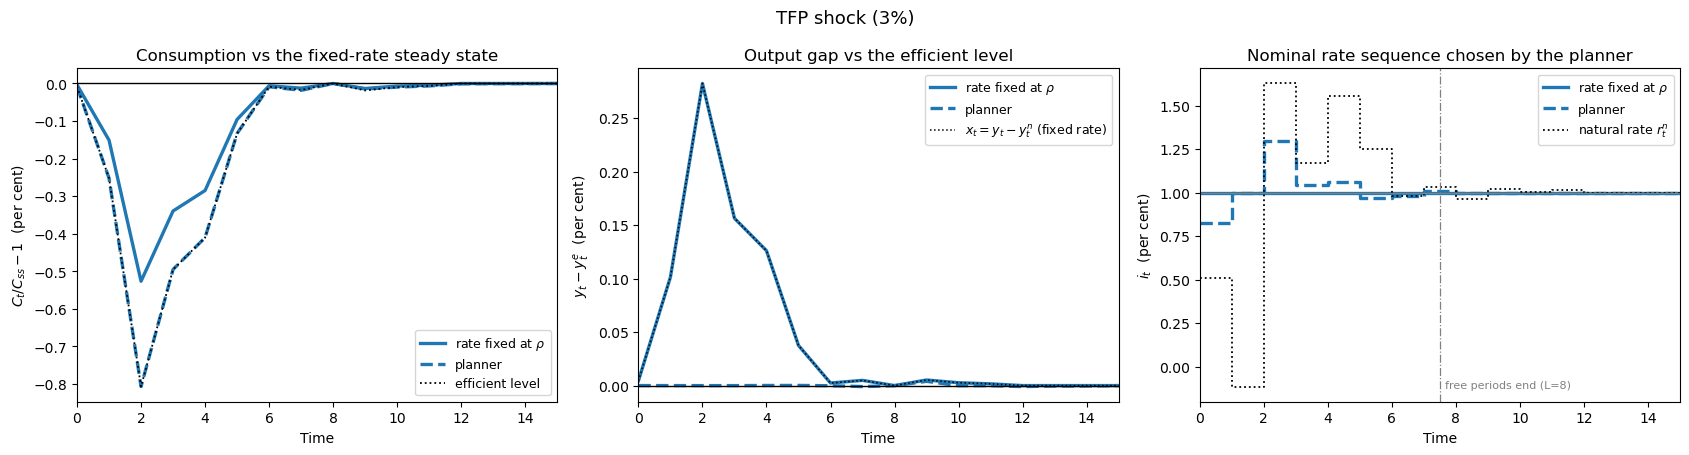

In [14]:
H = 16
COLOURS = {'TFP shock (3%)': 'C0', 'Demand shock (1%)': 'C1'}
FNAMES = {'TFP shock (3%)': '../semi_endo_planner_consumption_A.png',
          'Demand shock (1%)': '../semi_endo_planner_consumption_demand.png'}


def shock_figure(name, horizon=H, table=None, fname=None, suptitle=None):
    """Left: consumption vs the fixed-rate steady state.  Right: the chosen rate path.

    `table` defaults to the time-to-build `summary`; section 9 passes `summary_notb`.
    """
    r_opt, s_opt, s_base = (summary if table is None else table)[name]
    col = COLOURS[name]
    t = np.arange(horizon)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

    ax = axes[0]
    ax.plot(t, 100 * (np.exp(s_base['y_phys'][:horizon]) - 1), color=col, lw=2.4,
            label=r'rate fixed at $\rho$')
    ax.plot(t, 100 * (np.exp(s_opt['y_phys'][:horizon]) - 1), color=col, lw=2.4, ls='--',
            label='planner')
    ax.plot(t, 100 * (np.exp(s_opt['y_eff'][:horizon]) - 1), color='k', lw=1.3, ls=':',
            label='efficient level')
    ax.axhline(0, color='k', lw=1.0)
    ax.set_xlim(0, horizon - 1)
    ax.set_xlabel('Time'); ax.set_ylabel(r'$C_t/C_{ss}-1$  (per cent)')
    ax.set_title('Consumption vs the fixed-rate steady state')
    ax.legend(fontsize=9)

    ax = axes[1]
    ax.plot(t, 100 * (s_base['y_phys'] - s_base['y_eff'])[:horizon], color=col, lw=2.4,
            label=r'rate fixed at $\rho$')
    ax.plot(t, 100 * (s_opt['y_phys'] - s_opt['y_eff'])[:horizon], color=col, lw=2.4,
            ls='--', label='planner')
    ax.plot(t, 100 * s_base['x'][:horizon], color='k', lw=1.1, ls=':',
            label=r'$x_t=y_t-y^n_t$ (fixed rate)')
    ax.axhline(0, color='k', lw=1.0)
    ax.set_xlim(0, horizon - 1)
    ax.set_xlabel('Time'); ax.set_ylabel(r'$y_t-y^e_t$  (per cent)')
    ax.set_title('Output gap vs the efficient level')
    ax.legend(fontsize=9)

    ax = axes[2]
    ax.step(t, 100 * s_base['i'][:horizon], where='post', color=col, lw=2.4,
            label=r'rate fixed at $\rho$')
    ax.step(t, 100 * s_opt['i'][:horizon], where='post', color=col, lw=2.4, ls='--',
            label='planner')
    ax.step(t, 100 * s_base['r_nat'][:horizon], where='post', color='k', lw=1.3, ls=':',
            label=r'natural rate $r^n_t$')
    ax.axhline(100 * rho, color='grey', lw=0.9)
    L_free = len(r_opt)
    if L_free < horizon:
        ax.axvline(L_free - 0.5, color='grey', lw=0.9, ls='-.')
        ax.annotate(f'free periods end (L={L_free})', xy=(L_free - 0.5, ax.get_ylim()[0]),
                    xytext=(4, 8), textcoords='offset points', fontsize=8,
                    color='grey', va='bottom')
    ax.set_xlim(0, horizon - 1)
    ax.set_xlabel('Time'); ax.set_ylabel('$i_t$  (per cent)')
    ax.set_title('Nominal rate sequence chosen by the planner')
    ax.legend(fontsize=9)

    fig.suptitle(name if suptitle is None else suptitle, fontsize=13)
    fig.tight_layout()
    # fig.savefig, not plt.savefig: the pyplot version targets whatever gcf() happens
    # to be, and on the second call in a cell that is not this figure -- the previous
    # run silently wrote only the first figure of each pair.
    out = FNAMES[name] if fname is None else fname
    fig.savefig(out, dpi=150, bbox_inches='tight')
    print(f'wrote {os.path.abspath(out)}  ({os.path.getsize(out)} bytes)')
    plt.show()
    plt.close(fig)


shock_figure('TFP shock (3%)')

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_planner_consumption_demand.png  (112058 bytes)


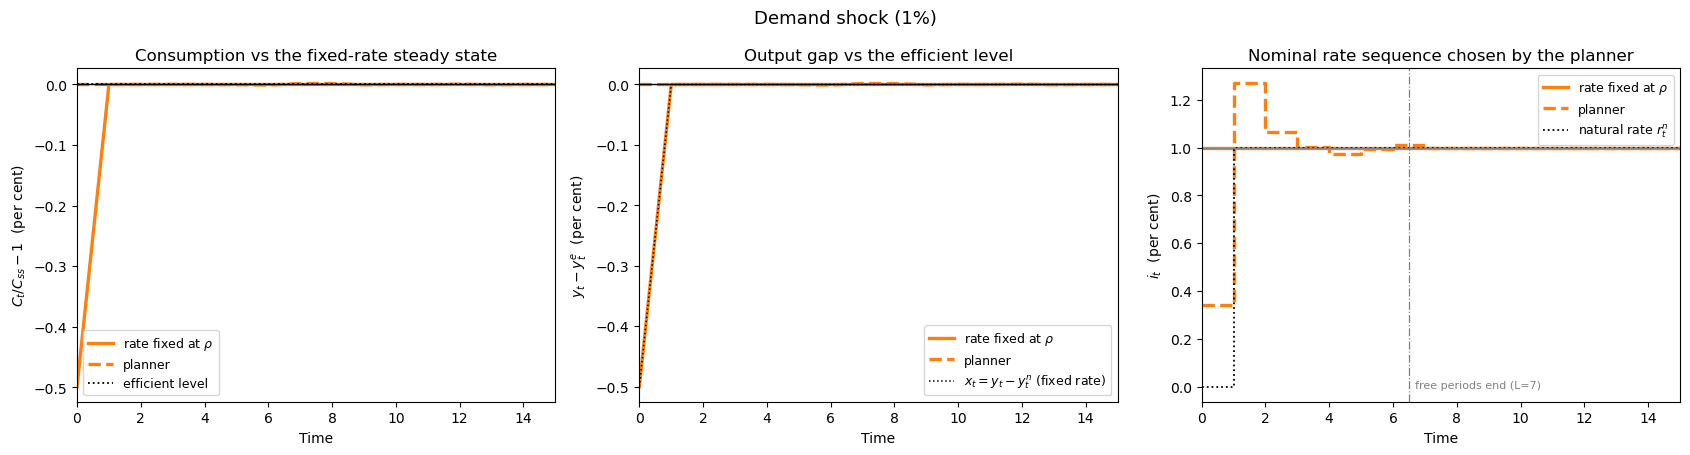

In [15]:
shock_figure('Demand shock (1%)')

Reading the figure — the two shocks ask different things of the planner, but neither gets
what it asks for exactly. Both panels plot the $L=18$ optimum, the horizon at which the
objective is within $10^{-8}$ of the best found.

* **Demand shock.** Physical productivity never moves, so the efficient level of
  consumption *is* the steady state (the dotted line lies on zero). Under a fixed rate
  consumption drops $0.50\%$ on impact and is back at $C_{ss}$ from $t=1$: with the rate
  pinned the discount block is constant, prices never move, and the shock is a pure
  Euler-equation event at $t=0$ with nothing to propagate. The planner holds consumption at
  $C_{ss}$ to within $0.007$pp at its worst — but it takes eighteen free periods to do it,
  not two, and the residual is still falling at $L=20$.
* **TFP shock.** A $3\%$ productivity decline lowers the *efficient* level of consumption to
  $\varphi_{ya}\,a^{\text{phys}} = -0.81\%$ at its trough. Under a fixed rate consumption
  falls only $0.59\%$ — it is **too high** relative to what is efficient, by about $0.22$
  percentage points. So the planner's optimal policy takes consumption *further down*, onto
  the dotted line. The planner line sitting below the fixed-rate line is the correct answer,
  not a perverse one: a supply shock should be accommodated, not offset.
* In both cases the planner tracks the efficient path closely but not exactly — the residual
  is $5.1\times10^{-5}$ for the TFP shock and $7.2\times10^{-5}$ for the demand shock at the
  plotted horizon, which is the "no finite $L$ attains the first best" statement of section 4
  in picture form.

The **middle panel** is the same information in the more familiar form. Under a fixed rate
the TFP shock opens a *positive* gap of about $+0.22$pp — output above efficient, because an
adverse supply shock is inflationary and a pinned nominal rate therefore eases in real
terms. The demand shock opens a negative one of $-0.50$pp. The planner nearly closes both.
The dotted line is the conventional gap $x_t$ against the *natural* level; it sits almost on
top of the welfare-relevant gap, which is the decomposition above saying the financing wedge
is small — $2.8\%$ of the gap at its peak for the TFP shock, and identically zero for the
demand shock.

On the **rate panels**: the sequence is drawn over the whole horizon, so the flat stretch
after the dash-dotted marker is the tail pinned at $\rho$, not a choice. The demand shock's
path is a deep cut at $t=0$ ($i_0\approx0.09\%$ against $\rho=1\%$) followed by a slow return
to $\rho$ from below — not the textbook $i_t=r^n_t$, because every move also moves firms'
prices over the lag $\tau$ and the planner has to unwind its own impulse. The TFP shock's
path oscillates around $r^n_t$ rather than tracking it, for the cohort reason set out in
`planner_adjusted_consumption.ipynb`.

Two things worth keeping straight. The benchmark here is the **fixed-rate steady state**,
which is constant and identical across both experiments — it is not the efficient path,
and for the TFP shock the two differ. And the oscillation documented in
`planner_adjusted_consumption.ipynb` lives in the **rate path**, not in consumption: the
planner alternates the rate precisely so that consumption does *not* alternate.

## 9. The same problem without time to build

Everything above is repeated with $\tau_i\equiv0$ in both places — no discount lag, and the
TFP shock hitting every firm at $t=0$ instead of arriving in cohorts. Same solver, same
welfare criterion, same figures, same fixed-rate steady state as the benchmark.

This is the flexible-price limit of the model, so it is the natural control: whatever is
left in the answer here is *not* coming from time to produce.

**This section is numerically identical before and after the section-2b correction.** With
$\tau_i\equiv0$ the discount block indexes column $0$ of the cumulative discount product,
which is $1$ regardless of what the rate matrix holds — so the truncation had nothing to
truncate. That makes it a clean control for the correction as well as for time to build.

In [16]:
CASES_NOTB = {n: dict(kw, time_to_build=False, shock_ttb=False) for n, kw in CASES.items()}

results_notb = {}
for name, kw in CASES_NOTB.items():
    print('=' * 96); print(f'{name}  --  no time to build'); print('=' * 96)
    results_notb[name] = escalate(kw, L_range=range(1, 9))
    print()

TFP shock (3%)  --  no time to build
  L            objective   peak |y-y_eff|    last i   sequence
------------------------------------------------------------------------------------------------
  1      34.785190187872        3.346e-08   0.02523   [0.02523]
  2      34.785190187872        5.245e-08   0.01000   [0.02523 0.01   ]
  3      34.785190187872        1.593e-07   0.01000   [0.02523 0.01    0.01   ]


  4      34.785190187872        4.596e-08   0.01000   [0.02523 0.01    0.01    0.01   ]


  5      34.785190187872        9.140e-08   0.01000   [0.02523 0.01    0.01    0.01    0.01   ]


  6      34.785190187872        1.954e-07   0.01000   [0.02523 0.01    0.01    0.01    0.01    0.01   ]


  7      34.785190187872        1.108e-07   0.01000   [0.02523 0.01    0.01    0.01    0.01    0.01   ] ...


  8      34.785190187872        1.499e-07   0.01000   [0.02523 0.01    0.01    0.01    0.01    0.01   ] ...

-> best objective 34.785190187872 over L <= 8; within 1e-08 of it from L = 1
   objective monotone in L: False
   peak gap decays geometrically, ratio ~ 1.267 per extra free period
   free periods to bring the peak gap below 0.001: 1
   free periods to bring the peak gap below 0.0001: 1
   gap at L = 8: 1.499e-07  (not zero -- see the docstring)

Demand shock (1%)  --  no time to build
  L            objective   peak |y-y_eff|    last i   sequence
------------------------------------------------------------------------------------------------
  1      34.741113516333        4.337e-18   0.00000   [0.]
  2      34.741113516333        4.311e-08   0.01000   [0.   0.01]
  3      34.741113516333        1.900e-08   0.01000   [0.   0.01 0.01]


  4      34.741113516333        1.206e-07   0.01000   [0.   0.01 0.01 0.01]
  5      34.741113516333        1.114e-07   0.01000   [0.   0.01 0.01 0.01 0.01]


  6      34.741113516333        8.838e-08   0.01000   [0.   0.01 0.01 0.01 0.01 0.01]


  7      34.741113516333        2.796e-07   0.01000   [0.   0.01 0.01 0.01 0.01 0.01] ...


  8      34.741113516333        1.741e-07   0.01000   [0.   0.01 0.01 0.01 0.01 0.01] ...

-> best objective 34.741113516333 over L <= 8; within 1e-08 of it from L = 1
   objective monotone in L: False
   peak gap decays geometrically, ratio ~ 2.370 per extra free period
   free periods to bring the peak gap below 0.001: 1
   free periods to bring the peak gap below 0.0001: 1
   gap at L = 8: 1.741e-07  (not zero -- see the docstring)



In [17]:
w = 44
summary_notb = {}
for name, kw in CASES_NOTB.items():
    hist, L_conv = results_notb[name]
    r_opt, f_opt, s_opt = hist[L_conv]
    s_base = solve(np.ones(3) * rho, **kw)
    U_b, UC_b, UN_b = welfare(s_base)
    U_o = welfare(s_opt)[0]
    summary_notb[name] = (r_opt, s_opt, s_base)
    print('=' * 78); print(f'{name}  --  no time to build'); print('=' * 78)
    print(f'{"free periods needed (objective converged)":<{w}}: {L_conv}')
    print(f'{"utility, no policy change":<{w}}: {U_b:.10f}')
    print(f'{"utility, planner":<{w}}: {U_o:.10f}')
    print(f'{"welfare gain (consumption equivalent)":<{w}}: '
          f'{100 * cons_equivalent(U_o, UC_b, UN_b):+.6f}% of ss C')
    print(f'{"peak |y-y_eff|, no policy change":<{w}}: '
          f'{np.max(np.abs(s_base["y_phys"] - s_base["y_eff"])):.4e}')
    print(f'{"peak |y-y_eff|, planner":<{w}}: '
          f'{np.max(np.abs(s_opt["y_phys"] - s_opt["y_eff"])):.4e}')
    print(f'{"optimum on a bound of [0, 0.05]":<{w}}: '
          f'{bool(np.any(np.isclose(r_opt, 0.0) | np.isclose(r_opt, 0.05)))}')
    print(f'{"optimal rate path":<{w}}: {np.round(r_opt[:8], 5)}')
    print(f'{"natural rate r^n_t, first 4":<{w}}: {np.round(s_base["r_nat"][:4], 5)}')
    print(f'{"implied i = r^n + pi_fwd, first 4":<{w}}: '
          f'{np.round((s_base["r_nat"] + np.r_[s_base["pi"][1:], 0.0])[:4], 5)}')
    print(f'{"physical TFP trough a_phys":<{w}}: {s_opt["a_phys"].min():.6f}')
    print(f'{"peak |d| (discount content)":<{w}}: {np.max(np.abs(s_opt["d"])):.4e}')
    print()

print('=' * 78); print('time to build vs none, side by side'); print('=' * 78)
print(f'{"case":<20}{"ttb":>6}{"L":>4}{"U planner":>17}{"peak|gap| base":>16}'
      f'{"a_phys trough":>15}   i[:4]')
print('-' * 104)
for name in CASES:
    for lab, tab, res in [('yes', summary, results), ('no', summary_notb, results_notb)]:
        r_, s_o, s_b = tab[name]
        print(f'{name:<20}{lab:>6}{len(r_):>4}{welfare(s_o)[0]:>17.9f}'
              f'{np.max(np.abs(s_b["y_phys"] - s_b["y_eff"])):>16.3e}'
              f'{s_b["a_phys"].min():>15.6f}   {np.round(r_[:4], 5)}')

TFP shock (3%)  --  no time to build
free periods needed (objective converged)   : 1
utility, no policy change                   : -34.7853094444
utility, planner                            : -34.7851901879
welfare gain (consumption equivalent)       : +0.000457% of ss C
peak |y-y_eff|, no policy change            : 7.6148e-03
peak |y-y_eff|, planner                     : 3.3464e-08
optimum on a bound of [0, 0.05]             : False
optimal rate path                           : [0.02523]
natural rate r^n_t, first 4                 : [0.05569 0.01    0.01    0.01   ]
implied i = r^n + pi_fwd, first 4           : [0.02523 0.01    0.01    0.01   ]
physical TFP trough a_phys                  : -0.030459
peak |d| (discount content)                 : 0.0000e+00

Demand shock (1%)  --  no time to build
free periods needed (objective converged)   : 1
utility, no policy change                   : -34.7411628545
utility, planner                            : -34.7411135163
welfare gain (consumpt

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_planner_consumption_A_notb.png  (116745 bytes)


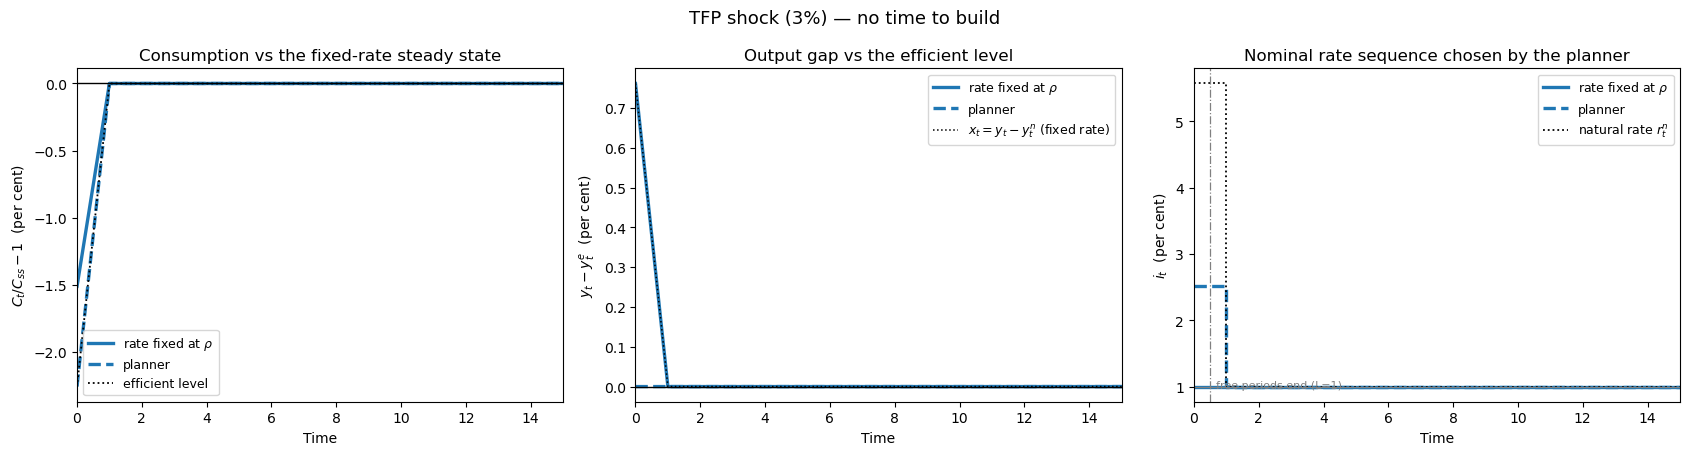

wrote /Users/samuelzhao/Documents/GitHub/shocky_shocks/semi_endo_planner_consumption_demand_notb.png  (106083 bytes)


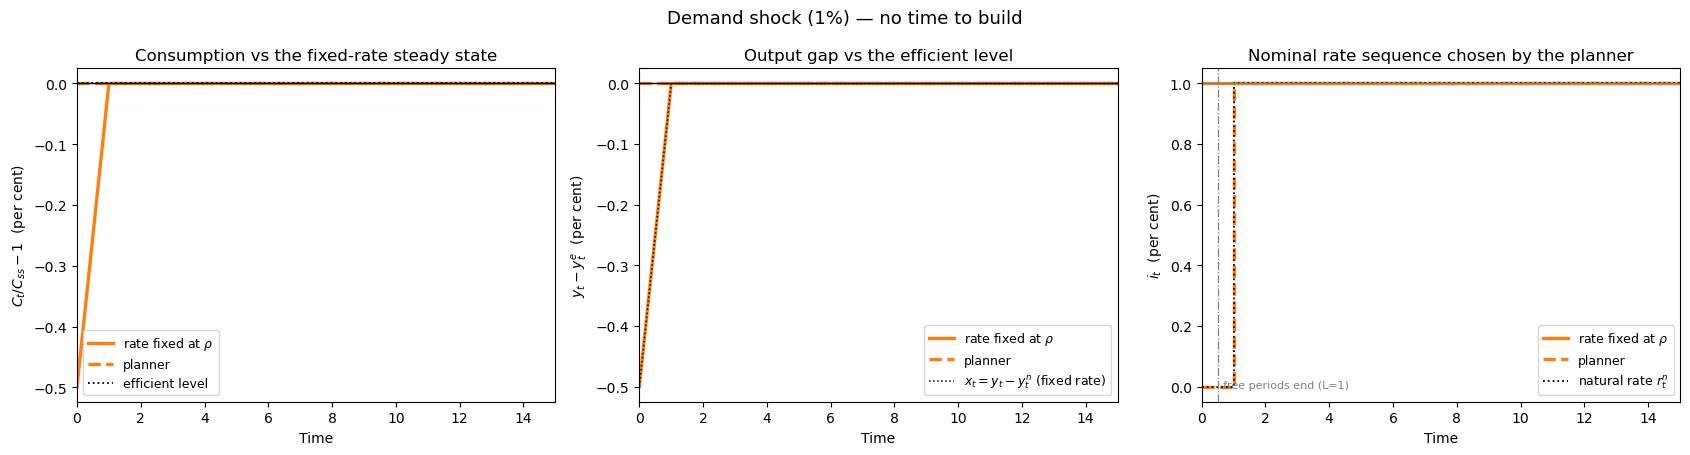

In [18]:
FNAMES_NOTB = {'TFP shock (3%)': '../semi_endo_planner_consumption_A_notb.png',
               'Demand shock (1%)': '../semi_endo_planner_consumption_demand_notb.png'}

for name in CASES:
    shock_figure(name, table=summary_notb, fname=FNAMES_NOTB[name],
                 suptitle=f'{name} — no time to build')

Reading section 9 against the time-to-build case, the flexible-price limit is a clean
control and it isolates what time to produce is actually doing.

* **One free period is enough, for both shocks.** $L=1$ attains the first best exactly
  ($|y-y^e|\sim3\times10^{-8}$ for the TFP shock, $4\times10^{-18}$ for the demand shock)
  against a gap still falling at $L=20$ with time to build. The whole "policy cannot
  neutralise the shock" result is a time-to-produce phenomenon, as section 4 claims — and
  with the corrected rate matrix the contrast is sharper than before, because it is now
  *exact attainment versus no attainment at any horizon*, not eleven free periods versus two.

* **And the rule is the textbook one.** The chosen rate equals $r^n_t+\pi_{t+1}$ period by
  period — printed above as *implied i* next to the optimum, and they agree to five
  decimals. For the TFP shock that is $i_0=2.52\%$ against a natural rate of $5.57\%$, the
  difference being the $-3.05\%$ of expected deflation as the price level falls back. For
  the demand shock it is $i_0=r^n_0=0$, which sits exactly on the lower bound — an accident
  of the calibration, since $r^n_0=\rho-\texttt{D\_SHOCK}=0.01-0.01$.

* **No oscillation, and no slow return.** The alternating path of section 6 is gone, and so
  is the demand shock's gradual climb back to $\rho$: a single move, then $\rho$ forever.
  That is the direct confirmation of the cohort explanation — with $\tau_i\equiv0$ there are
  no cohorts for the rate to be right for one and wrong for the next, and no production
  window for a move to leak into.

* **But the TFP shock is three times more costly.** Physical TFP troughs at $-3.05\%$
  rather than $-1.08\%$, because the CES aggregate now takes the whole shock at once instead
  of averaging it across cohorts. The planner's welfare gain rises to $+0.00046\%$ of
  steady-state consumption from $+0.00007\%$.

The last two points are the interesting pair, and they pull in opposite directions:
staggering *cushions* the shock — it is what keeps measured TFP from falling the full $3\%$
— while simultaneously making the shock impossible for policy to neutralise. Time to
produce is not simply a friction to be removed here; it is an averaging device with a
policy cost attached, and the correction of section 2b makes that cost larger, not smaller.

The demand shock's welfare gain is the *same* here as with time to build ($+0.000189\%$),
which is point 3 of the summary: time to produce does not change what the planner can
ultimately achieve against a preference shock, only how many periods of discretion it needs
to get there — one, against more than twenty.